In [38]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

In [39]:
rng = np.random.default_rng(42)

In [40]:
def box_muller(n):
    u1 = rng.random(n)
    u2 = rng.random(n)

    u1 = np.maximum(u1, 1e-10)

    z1 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
    z2 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2)

    return np.column_stack((z1, z2))

In [41]:
def generate_gaussian(n, mu, sigma_x, sigma_y=None,
                      covariance_type="spherical", rho=0):

    z = box_muller(n)

    if sigma_y is None:
        sigma_y = sigma_x

    if covariance_type == "spherical":
        x1 = mu[0] + sigma_x * z[:, 0]
        x2 = mu[1] + sigma_x * z[:, 1]

    elif covariance_type == "diagonal":
        x1 = mu[0] + sigma_x * z[:, 0]
        x2 = mu[1] + sigma_y * z[:, 1]

    elif covariance_type == "full":
        x1 = mu[0] + sigma_x * z[:, 0]
        x2 = mu[1] + sigma_y * (
            rho * z[:, 0] +
            np.sqrt(1 - rho**2) * z[:, 1]
        )

    else:
        raise ValueError("Invalid covariance type")

    return np.column_stack((x1, x2))

In [42]:
n_samples = 1500

K = 3

pi = [0.2, 0.3, 0.5]


means_class1 = [
    [2, 2],
    [5, 5],
    [2, 6]
]

means_class2 = [
    [10, 2],
    [13, 5],
    [10, 6]
]

sigma_x = 1.0
sigma_y = 0.5

rho = 0.6

In [43]:
class LCG:
    def __init__(self, seed=42, a=1664525, b=1013904223, m=2**32):
        self.x = seed
        self.a = a
        self.b = b
        self.m = m

    def generate(self, n):
        values = []

        for i in range(n):
            self.x = (self.a * self.x + self.b) % self.m
            values.append(self.x / self.m)

        return np.array(values)


lcg = LCG(seed=42)

uniform_values = lcg.generate(n_samples)

print("Number of uniform values generated:", len(uniform_values))
print("\nGenerated uniform values:")
print(uniform_values)

print("\nMinimum value:", uniform_values.min())
print("Maximum value:", uniform_values.max())
print("All values in [0, 1):",
      np.all((uniform_values >= 0) & (uniform_values < 1)))

Number of uniform values generated: 1500

Generated uniform values:
[0.2523 0.0881 0.5773 0.2226 0.3757 0.0257 0.4473 0.1185 0.8738 0.9946
 0.8532 0.4997 0.642  0.8615 0.5965 0.0908 0.1402 0.9501 0.9246 0.8895
 0.5505 0.1805 0.5501 0.259  0.9431 0.8215 0.1553 0.8294 0.4669 0.0607
 0.0225 0.5373 0.83   0.8453 0.6809 0.3808 0.5857 0.6964 0.7114 0.7186
 0.9903 0.4498 0.0979 0.1916 0.4474 0.127  0.7688 0.5937 0.8046 0.3894
 0.2158 0.2721 0.0191 0.278  0.334  0.8829 0.9559 0.1927 0.8713 0.5823
 0.3367 0.3143 0.1294 0.98   0.103  0.9215 0.8057 0.433  0.7101 0.3067
 0.1186 0.5092 0.1174 0.2435 0.6041 0.6978 0.4907 0.2097 0.2273 0.6943
 0.8818 0.817  0.6972 0.8395 0.4016 0.1532 0.1263 0.5398 0.6517 0.9878
 0.426  0.747  0.4303 0.0455 0.0773 0.8257 0.9787 0.7997 0.1687 0.3866
 0.2832 0.4899 0.841  0.9138 0.1976 0.316  0.53   0.2641 0.4039 0.0124
 0.648  0.3667 0.4744 0.2548 0.5935 0.7007 0.5528 0.6036 0.2319 0.3798
 0.4183 0.936  0.2354 0.9208 0.9499 0.5714 0.9249 0.0254 0.2552 0.5411
 0.5022 0

In [44]:
def select_components(uniform_values, weights):
    weights = np.asarray(weights, dtype=float)

    if len(weights) == 0:
        raise ValueError("Enter at least one probability")

    if np.any(~np.isfinite(weights)) or np.any(weights < 0):
        raise ValueError("Probabilities must be finite and non-negative")

    if not np.isclose(np.sum(weights), 1.0):
        raise ValueError("Probabilities must add up to 1")

    split_points = np.cumsum(weights)
    split_points[-1] = 1.0

    components = np.searchsorted(
        split_points, uniform_values, side="right"
    )

    return split_points, components


pi = [0.2, 0.3, 0.5]

split_points, components = select_components(uniform_values, pi)

print("Probabilities:", pi)
print("Split points:", split_points)
print()

lower = 0.0

for i in range(len(pi)):
    upper = split_points[i]
    count = np.sum(components == i)

    print(f"Mixture {i + 1}")
    print(f"Interval: {lower:.2f} <= u < {upper:.2f}")
    print(f"Number of values: {count}")
    print()

    lower = upper

print("First 20 values and their assigned mixtures:")

for i in range(min(20, len(uniform_values))):
    print(f"{uniform_values[i]:.4f} -> Mixture {components[i] + 1}")

Probabilities: [0.2, 0.3, 0.5]
Split points: [0.2 0.5 1. ]

Mixture 1
Interval: 0.00 <= u < 0.20
Number of values: 266

Mixture 2
Interval: 0.20 <= u < 0.50
Number of values: 465

Mixture 3
Interval: 0.50 <= u < 1.00
Number of values: 769

First 20 values and their assigned mixtures:
0.2523 -> Mixture 2
0.0881 -> Mixture 1
0.5773 -> Mixture 3
0.2226 -> Mixture 2
0.3757 -> Mixture 2
0.0257 -> Mixture 1
0.4473 -> Mixture 2
0.1185 -> Mixture 1
0.8738 -> Mixture 3
0.9946 -> Mixture 3
0.8532 -> Mixture 3
0.4997 -> Mixture 2
0.6420 -> Mixture 3
0.8615 -> Mixture 3
0.5965 -> Mixture 3
0.0908 -> Mixture 1
0.1402 -> Mixture 1
0.9501 -> Mixture 3
0.9246 -> Mixture 3
0.8895 -> Mixture 3


In [45]:
def check_split(uniform_values, split_points, components, weights):
    n = len(uniform_values)
    lower = 0.0
    total_count = 0

    print(
        f"{'Mixture':<12}"
        f"{'Interval':<18}"
        f"{'Count':<10}"
        f"{'Expected':<12}"
        f"{'Check'}"
    )
    print("-" * 65)

    for i, upper in enumerate(split_points):
        assigned_count = np.sum(components == i)

        interval_count = np.sum(
            (uniform_values >= lower) &
            (uniform_values < upper)
        )

        expected_count = n * weights[i]

        if assigned_count == interval_count:
            check = "Correct"
        else:
            check = "Error"

        interval = f"[{lower:.2f}, {upper:.2f})"

        print(
            f"{i + 1:<12}"
            f"{interval:<18}"
            f"{assigned_count:<10}"
            f"{expected_count:<12.1f}"
            f"{check}"
        )

        total_count += assigned_count
        lower = upper

    print("-" * 65)
    print("Total assigned:", total_count, "out of", n)


check_split(uniform_values, split_points, components, pi)

Mixture     Interval          Count     Expected    Check
-----------------------------------------------------------------
1           [0.00, 0.20)      266       300.0       Correct
2           [0.20, 0.50)      465       450.0       Correct
3           [0.50, 1.00)      769       750.0       Correct
-----------------------------------------------------------------
Total assigned: 1500 out of 1500


In [46]:
def generate_gmm(n, means, weights, covariance_type,
                 sigma_x, sigma_y=None, rho=0):

    if n <= 0:
        raise ValueError("Number of samples must be greater than 0")

    if len(means) != len(weights):
        raise ValueError("Number of means and probabilities must match")

    uniform_values = lcg.generate(n)

    split_points, components = select_components(
        uniform_values, weights
    )

    X = np.zeros((n, 2))

    for i in range(len(means)):
        count = np.sum(components == i)

        if count > 0:
            X[components == i] = generate_gaussian(
                count,
                means[i],
                sigma_x,
                sigma_y,
                covariance_type,
                rho
            )

    return X, components

In [47]:
X1, component1 = generate_gmm(
    n_samples,
    means_class1,
    pi,
    "full",
    sigma_x,
    sigma_y,
    rho
)

X2, component2 = generate_gmm(
    n_samples,
    means_class2,
    pi,
    "full",
    sigma_x,
    sigma_y,
    rho
)

np.set_printoptions(threshold=np.inf, precision=4)

print("\n========== CLASS 1 ==========")

for i in range(len(pi)):
    mixture_points = X1[component1 == i]

    print(f"\nMixture {i + 1}")
    print("Number of Gaussian points:", len(mixture_points))
    print("Gaussian data points:")
    print(mixture_points[:5])

print("\n========== CLASS 2 ==========")

for i in range(len(pi)):
    mixture_points = X2[component2 == i]

    print(f"\nMixture {i + 1}")
    print("Number of Gaussian points:", len(mixture_points))
    print("Gaussian data points:")
    print(mixture_points[:5])

print("\nClass 1 shape:", X1.shape)
print("Class 2 shape:", X2.shape)


========== CLASS 1 ==========

Mixture 1
Number of Gaussian points: 336
Gaussian data points:
[[2.5918 2.3386]
 [1.8049 1.4341]
 [2.4762 2.2547]
 [2.7812 2.1013]
 [3.4127 3.0846]]

Mixture 2
Number of Gaussian points: 419
Gaussian data points:
[[4.9573 4.9652]
 [4.7938 5.2651]
 [4.95   5.392 ]
 [3.8268 4.3667]
 [4.6448 4.9836]]

Mixture 3
Number of Gaussian points: 745
Gaussian data points:
[[3.5655e-03 5.2901e+00]
 [3.5169e+00 6.0689e+00]
 [2.2619e+00 5.7064e+00]
 [2.7120e+00 6.3237e+00]
 [1.5743e+00 5.9536e+00]]

========== CLASS 2 ==========

Mixture 1
Number of Gaussian points: 277
Gaussian data points:
[[ 9.4014  1.7695]
 [ 9.5434  2.2281]
 [11.3239  2.8093]
 [ 9.6085  1.6191]
 [12.1738  2.8385]]

Mixture 2
Number of Gaussian points: 450
Gaussian data points:
[[11.4773  4.3934]
 [13.2693  5.3261]
 [11.8202  4.66  ]
 [13.2258  5.1962]
 [13.5134  5.4848]]

Mixture 3
Number of Gaussian points: 773
Gaussian data points:
[[11.1298  6.3516]
 [10.5192  6.7103]
 [10.1727  6.8293]
 [10.32

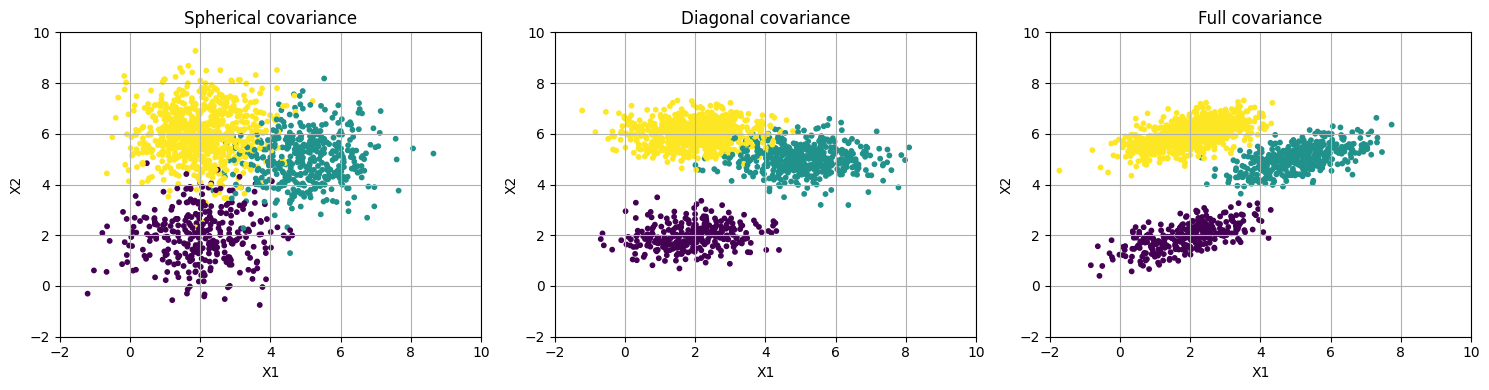

In [48]:
covariance_types = ["spherical", "diagonal", "full"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, cov_type in zip(axes, covariance_types):
    X, components = generate_gmm(
        1500, means_class1, pi, cov_type,
        sigma_x, sigma_y, rho
    )

    ax.scatter(X[:, 0], X[:, 1], c=components, s=10)
    ax.set_title(cov_type.capitalize() + " covariance")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-2, 10)
    ax.set_ylim(-2, 10)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [49]:
X1, component1 = generate_gmm(
    n_samples, means_class1, pi, "full",
    sigma_x, sigma_y, rho
)

X2, component2 = generate_gmm(
    n_samples, means_class2, pi, "full",
    sigma_x, sigma_y, rho
)

print("Class 1 data:", X1.shape)
print("Class 2 data:", X2.shape)

Class 1 data: (1500, 2)
Class 2 data: (1500, 2)


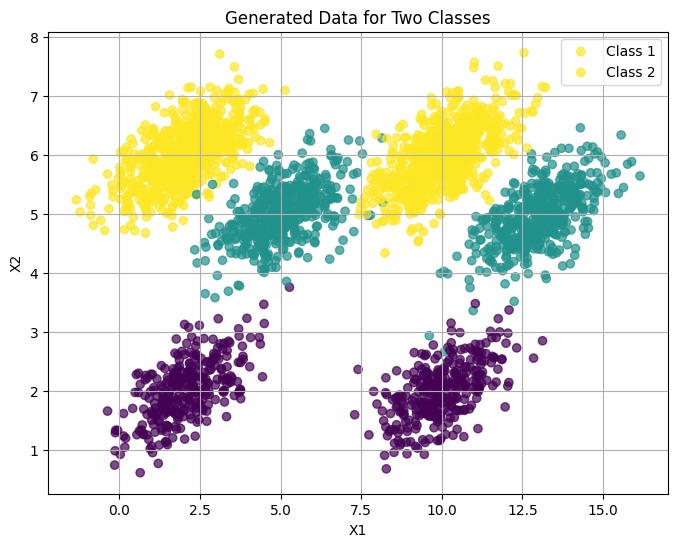

In [50]:
plt.figure(figsize=(8, 6))

plt.scatter(X1[:, 0], X1[:, 1], c=component1, label="Class 1", alpha=0.7)
plt.scatter(X2[:, 0], X2[:, 1], c=component2, label="Class 2", alpha=0.7)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Generated Data for Two Classes")
plt.legend()
plt.grid(True)
plt.show()

In [51]:
def shuffle_indices(n):
    return rng.permutation(n)

In [52]:
def train_test_split(X):
    indices = shuffle_indices(len(X))
    split = int(0.8 * len(X))

    train = X[indices[:split]]
    test = X[indices[split:]]

    return train, test

X1_train, X1_test = train_test_split(X1)
X2_train, X2_test = train_test_split(X2)

print("Class 1 training:", len(X1_train))
print("Class 1 testing:", len(X1_test))
print("Class 2 training:", len(X2_train))
print("Class 2 testing:", len(X2_test))

Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300


In [53]:
def kmeans(X, K, max_iterations=100):
    indices = shuffle_indices(len(X))
    centroids = X[indices[:K]].copy()

    for _ in range(max_iterations):
        distances = np.zeros((len(X), K))

        for j in range(K):
            distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

        labels = np.argmin(distances, axis=1)
        new_centroids = centroids.copy()

        for j in range(K):
            points = X[labels == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(points, axis=0)

        if np.sum((new_centroids - centroids)**2) < 1e-8:
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.zeros((len(X), K))

    for j in range(K):
        distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

    labels = np.argmin(distances, axis=1)

    return centroids, labels

In [54]:
centroids1, labels1 = kmeans(X1_train, K)
centroids2, labels2 = kmeans(X2_train, K)

print("Class 1 centroids:")
print(centroids1)

print("\nClass 2 centroids:")
print(centroids2)

Class 1 centroids:
[[5.0907 5.0913]
 [1.9015 5.9435]
 [1.9814 2.0135]]

Class 2 centroids:
[[ 9.9606  2.0285]
 [13.0736  5.1083]
 [ 9.9774  5.9388]]


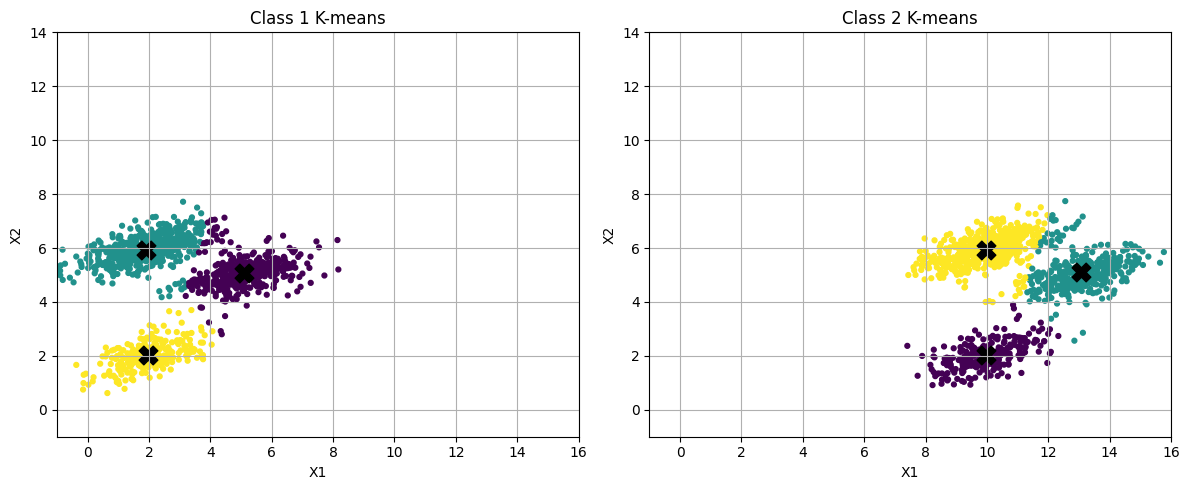

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X1_train[:, 0], X1_train[:, 1], c=labels1, s=12)
axes[0].scatter(centroids1[:, 0], centroids1[:, 1],
                marker="X", s=180, c="black")
axes[0].set_title("Class 1 K-means")

axes[1].scatter(X2_train[:, 0], X2_train[:, 1], c=labels2, s=12)
axes[1].scatter(centroids2[:, 0], centroids2[:, 1],
                marker="X", s=180, c="black")
axes[1].set_title("Class 2 K-means")

for ax in axes:
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-1, 16)
    ax.set_ylim(-1, 14)
    ax.grid(True)

plt.tight_layout()
plt.show()

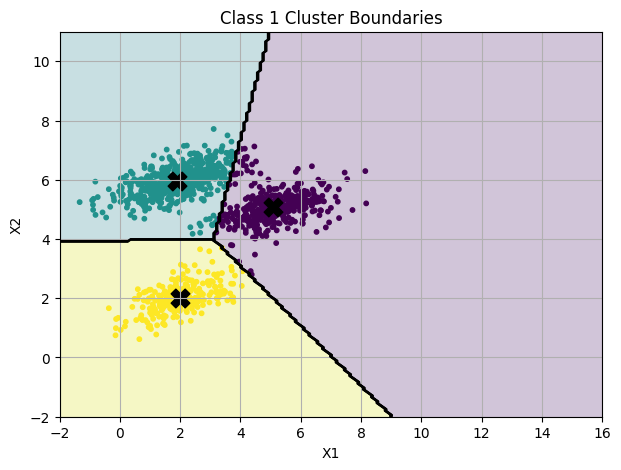

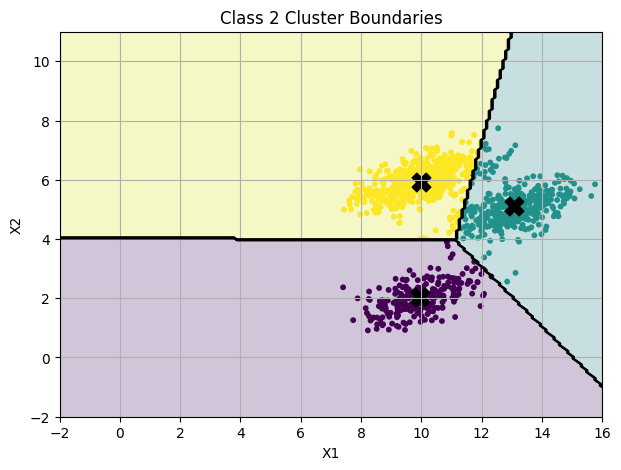

In [56]:

def plot_boundaries(X, centroids, labels, title):
    x_min, x_max = -2, 16
    y_min, y_max = -2, 11

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))
    distances = np.zeros((len(grid), len(centroids)))

    for j in range(len(centroids)):
        distances[:, j] = np.sum((grid - centroids[j])**2, axis=1)

    regions = np.argmin(distances, axis=1).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, regions, alpha=0.25)
    plt.contour(xx, yy, regions, colors="black", linewidths=1)

    plt.scatter(X[:, 0], X[:, 1], c=labels, s=10)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker="X", s=180, c="black")

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True)
    plt.show()

plot_boundaries(X1_train, centroids1, labels1, "Class 1 Cluster Boundaries")
plot_boundaries(X2_train, centroids2, labels2, "Class 2 Cluster Boundaries")


In [57]:
def calculate_distortion(X, centroids):
    distances = np.zeros((len(X), len(centroids)))

    for j in range(len(centroids)):
        distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

    return np.min(distances, axis=1)

def classify(X):
    distortion1 = calculate_distortion(X, centroids1)
    distortion2 = calculate_distortion(X, centroids2)

    predictions = np.where(distortion1 < distortion2, 0, 1)

    return predictions

In [58]:
X_test = np.vstack((X1_test, X2_test))

y_test = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

predictions = classify(X_test)

accuracy = np.mean(predictions == y_test) * 100

print("Total test samples:", len(X_test))
print("Correct predictions:", np.sum(predictions == y_test))
print("Incorrect predictions:", np.sum(predictions != y_test))
print("Classification accuracy:", round(accuracy, 2), "%")

Total test samples: 600
Correct predictions: 597
Incorrect predictions: 3
Classification accuracy: 99.5 %


In [59]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_test, predictions):
    confusion_matrix[actual, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[299   1]
 [  2 298]]


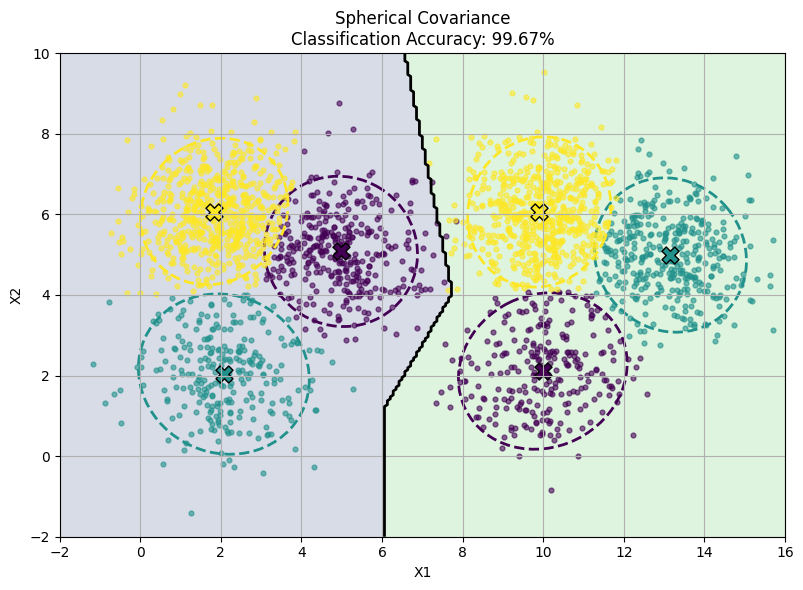

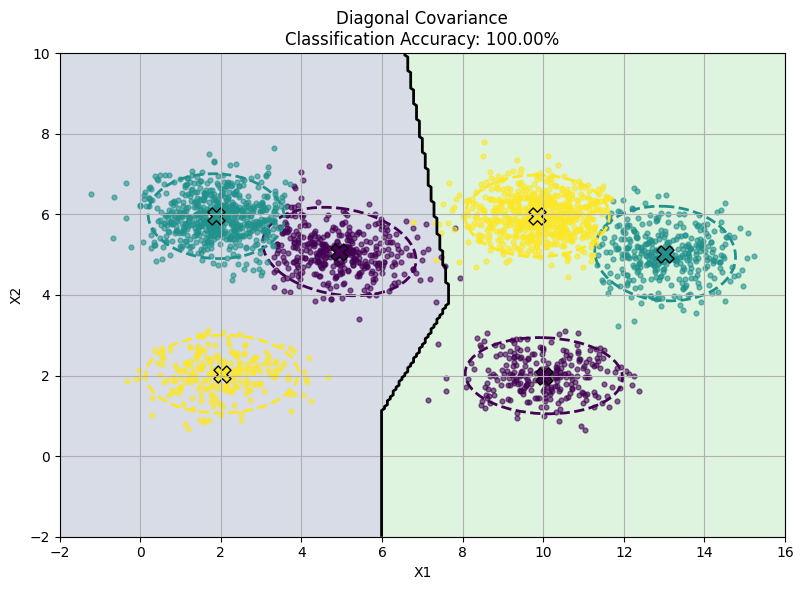

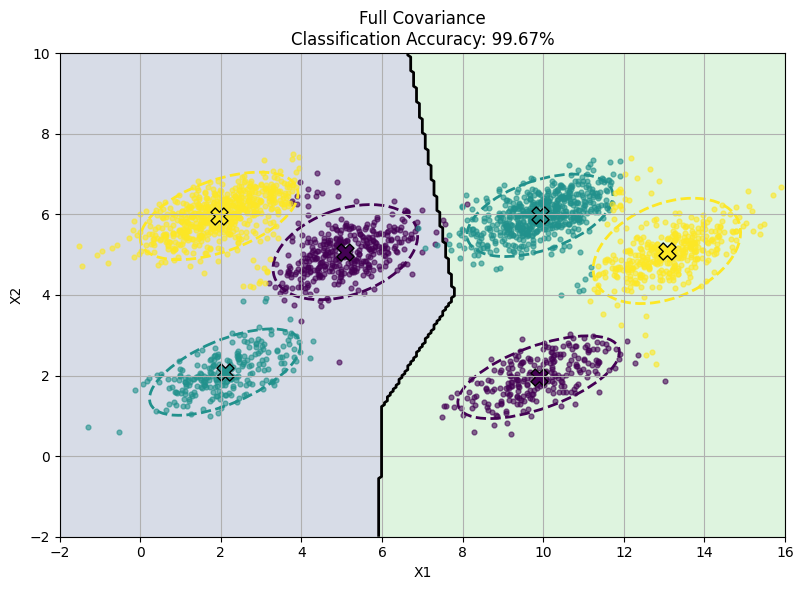

In [60]:
from matplotlib.patches import Ellipse

covariance_types = ["spherical", "diagonal", "full"]
colors = ["#440154", "#21918c", "#fde725"]

for cov_type in covariance_types:

    X1_cov, _ = generate_gmm(
        n_samples, means_class1, pi, cov_type,
        sigma_x, sigma_y, rho
    )

    X2_cov, _ = generate_gmm(
        n_samples, means_class2, pi, cov_type,
        sigma_x, sigma_y, rho
    )

    X1_train_cov, X1_test_cov = train_test_split(X1_cov)
    X2_train_cov, X2_test_cov = train_test_split(X2_cov)

    centroids1_cov, labels1_cov = kmeans(X1_train_cov, K)
    centroids2_cov, labels2_cov = kmeans(X2_train_cov, K)

    X_test_cov = np.vstack((X1_test_cov, X2_test_cov))

    y_test_cov = np.concatenate((
        np.zeros(len(X1_test_cov), dtype=int),
        np.ones(len(X2_test_cov), dtype=int)
    ))

    dist1 = calculate_distortion(X_test_cov, centroids1_cov)
    dist2 = calculate_distortion(X_test_cov, centroids2_cov)

    predictions_cov = np.where(dist1 < dist2, 0, 1)
    accuracy_cov = np.mean(predictions_cov == y_test_cov) * 100

    xx, yy = np.meshgrid(
        np.linspace(-2, 16, 250),
        np.linspace(-2, 10, 250)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))

    grid_dist1 = calculate_distortion(grid, centroids1_cov)
    grid_dist2 = calculate_distortion(grid, centroids2_cov)

    regions = np.where(grid_dist1 < grid_dist2, 0, 1)
    regions = regions.reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 6))

    ax.contourf(
        xx, yy, regions,
        levels=[-0.5, 0.5, 1.5],
        alpha=0.2
    )

    ax.contour(
        xx, yy, regions,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    for X_train, labels, centroids in [
        (X1_train_cov, labels1_cov, centroids1_cov),
        (X2_train_cov, labels2_cov, centroids2_cov)
    ]:

        for i in range(K):
            points = X_train[labels == i]

            ax.scatter(
                points[:, 0],
                points[:, 1],
                color=colors[i % len(colors)],
                s=12,
                alpha=0.6
            )

            ax.scatter(
                centroids[i, 0],
                centroids[i, 1],
                marker="X",
                s=150,
                color=colors[i % len(colors)],
                edgecolors="black"
            )

            if len(points) > 1:
                cov = np.cov(points, rowvar=False)

                values, vectors = np.linalg.eigh(cov)
                order = np.argsort(values)[::-1]

                values = values[order]
                vectors = vectors[:, order]

                angle = np.degrees(
                    np.arctan2(vectors[1, 0], vectors[0, 0])
                )

                width = 4 * np.sqrt(max(values[0], 0))
                height = 4 * np.sqrt(max(values[1], 0))

                ellipse = Ellipse(
                    centroids[i],
                    width=width,
                    height=height,
                    angle=angle,
                    fill=False,
                    edgecolor=colors[i % len(colors)],
                    linestyle="--",
                    linewidth=2
                )

                ax.add_patch(ellipse)

    ax.set_title(
        f"{cov_type.capitalize()} Covariance\n"
        f"Classification Accuracy: {accuracy_cov:.2f}%"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-2, 16)
    ax.set_ylim(-2, 10)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True)

    plt.tight_layout()
    plt.show()

In [61]:
X_train = np.vstack((X1_train, X2_train))

y_train = np.concatenate((
    np.zeros(len(X1_train), dtype=int),
    np.ones(len(X2_train), dtype=int)
))

X_test = np.vstack((X1_test, X2_test))

y_test = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (2400, 2)
Testing data shape: (600, 2)
Training labels shape: (2400,)
Testing labels shape: (600,)


In [62]:
import numpy as np

def gaussian_pdf(X, mean, covariance):
    """Calculate multivariate Gaussian probability density."""
    d = X.shape[1]
    covariance = covariance + 1e-6 * np.eye(d)

    sign, log_det = np.linalg.slogdet(covariance)
    if sign <= 0:
        covariance = covariance + 1e-4 * np.eye(d)
        sign, log_det = np.linalg.slogdet(covariance)

    diff = X - mean
    solved = np.linalg.solve(covariance, diff.T).T
    mahalanobis = np.sum(diff * solved, axis=1)

    log_pdf = -0.5 * (
        d * np.log(2 * np.pi) + log_det + mahalanobis
    )
    return np.exp(np.maximum(log_pdf, -700))


def train_gmm(X, K, max_iter=100, tol=1e-4, seed=42):
    """Train a full-covariance GMM using the EM algorithm."""
    rng = np.random.default_rng(seed)
    n, d = X.shape

    means = X[rng.choice(n, K, replace=False)].copy()
    global_cov = np.cov(X, rowvar=False)
    global_cov = np.atleast_2d(global_cov) + 1e-5 * np.eye(d)

    covariances = np.array([global_cov.copy() for _ in range(K)])
    weights = np.ones(K) / K
    previous_log_likelihood = -np.inf

    for iteration in range(max_iter):
        probabilities = np.column_stack([
            weights[k] * gaussian_pdf(X, means[k], covariances[k])
            for k in range(K)
        ])

        row_sums = np.maximum(probabilities.sum(axis=1), 1e-300)
        responsibilities = probabilities / row_sums[:, None]
        log_likelihood = np.sum(np.log(row_sums))

        Nk = responsibilities.sum(axis=0)
        Nk = np.maximum(Nk, 1e-8)

        weights = Nk / n
        means = (responsibilities.T @ X) / Nk[:, None]

        for k in range(K):
            diff = X - means[k]
            covariances[k] = (
                (diff * responsibilities[:, k, None]).T @ diff
            ) / Nk[k]
            covariances[k] += 1e-5 * np.eye(d)

        if abs(log_likelihood - previous_log_likelihood) < tol:
            break

        previous_log_likelihood = log_likelihood

    return {
        "weights": weights,
        "means": means,
        "covariances": covariances
    }


class1_train = X_train[y_train == 0]
class2_train = X_train[y_train == 1]

gmm1 = train_gmm(class1_train, K, seed=42)
gmm2 = train_gmm(class2_train, K, seed=43)

print("GMM for Class 1 trained successfully")
print("GMM for Class 2 trained successfully")

GMM for Class 1 trained successfully
GMM for Class 2 trained successfully


In [63]:

def gmm_score_samples(X, gmm):
    """Calculate log-likelihood of each sample under a trained GMM."""
    weights = gmm["weights"]
    means = gmm["means"]
    covariances = gmm["covariances"]

    component_log_probs = []

    for k in range(len(weights)):
        covariance = covariances[k]
        diff = X - means[k]

        sign, log_det = np.linalg.slogdet(covariance)
        if sign <= 0:
            covariance = covariance + 1e-4 * np.eye(X.shape[1])
            sign, log_det = np.linalg.slogdet(covariance)

        solved = np.linalg.solve(covariance, diff.T).T
        mahalanobis = np.sum(diff * solved, axis=1)

        log_pdf = -0.5 * (
            X.shape[1] * np.log(2 * np.pi)
            + log_det
            + mahalanobis
        )

        component_log_probs.append(np.log(weights[k] + 1e-300) + log_pdf)

    component_log_probs = np.array(component_log_probs).T

    row_max = np.max(component_log_probs, axis=1, keepdims=True)
    return (
        row_max[:, 0]
        + np.log(np.sum(np.exp(component_log_probs - row_max), axis=1))
    )


score1 = gmm_score_samples(X_test, gmm1)
score2 = gmm_score_samples(X_test, gmm2)

predictions = np.where(score1 > score2, 0, 1)

accuracy = np.mean(predictions == y_test) * 100

print("Number of test samples:", len(X_test))
print("Correct predictions:", np.sum(predictions == y_test))
print("Incorrect predictions:", np.sum(predictions != y_test))
print("Classification Accuracy:", round(accuracy, 2), "%")

Number of test samples: 600
Correct predictions: 599
Incorrect predictions: 1
Classification Accuracy: 99.83 %


In [64]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_test, predictions):
    confusion_matrix[actual, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[299   1]
 [  0 300]]


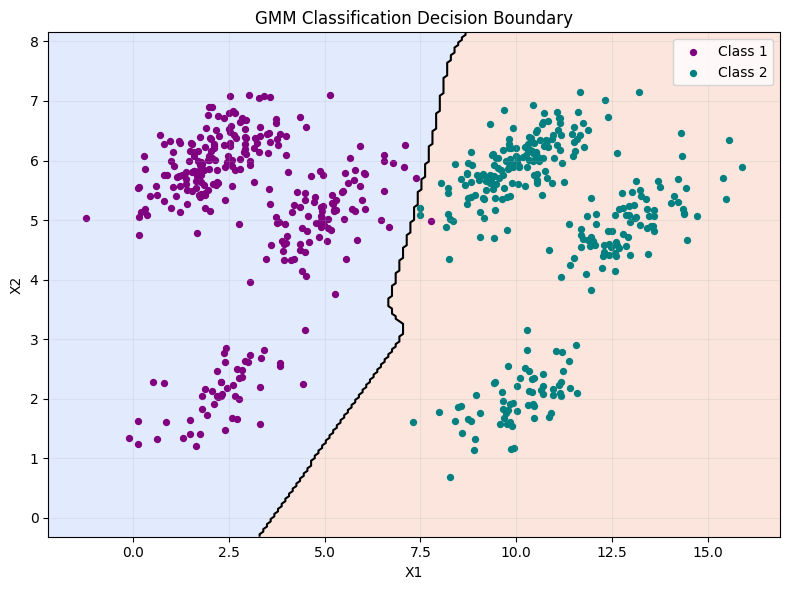

In [65]:
import matplotlib.pyplot as plt
import numpy as np

x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

score1_grid = gmm_score_samples(grid, gmm1)
score2_grid = gmm_score_samples(grid, gmm2)

Z = np.where(score1_grid > score2_grid, 0, 1)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    alpha=0.25,
    cmap="coolwarm"
)

plt.scatter(
    X_test[y_test == 0, 0], X_test[y_test == 0, 1],
    color="purple", s=18, label="Class 1"
)

plt.scatter(
    X_test[y_test == 1, 0], X_test[y_test == 1, 1],
    color="teal", s=18, label="Class 2"
)

plt.contour(
    xx, yy, Z,
    levels=[0.5],
    colors="black"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("GMM Classification Decision Boundary")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [66]:
from google.colab import files

uploaded = files.upload()

Saving Assignment7.ipynb to Assignment7.ipynb


In [67]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

zip_path = "TEAM_8.zip"
extract_path = "TEAM_8"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [68]:
for root, dirs, files_list in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files_list[:3]:
            print("  " * (level + 1) + file)

TEAM_8/
  dev/
    7/
      image_00001793.png
      image_00001411.png
      image_00003626.png
    4/
      image_00003143.png
      image_00001287.png
      image_00002439.png
    3/
      image_00002485.png
      image_00003593.png
      image_00000805.png
  test/
    7/
      image_00000302.png
      image_00001010.png
      image_00001527.png
    4/
      image_00002485.png
      image_00001287.png
      image_00002439.png
    3/
      image_00002151.png
      image_00000805.png
      image_00001941.png
  train/
    7/
      image_00006799.png
      image_00011746.png
      image_00014340.png
    4/
      image_00002485.png
      image_00005691.png
      image_00009743.png
    3/
      image_00011174.png
      image_00006085.png
      image_00010084.png


In [73]:
import os

dataset_path = "/content/TEAM_8"

for split in ["train", "dev", "test"]:
    print("\n", split.upper())

    for digit in ["3", "4", "7"]:
        folder = os.path.join(dataset_path, split, digit)

        if os.path.exists(folder):
            image_files = [
                f for f in os.listdir(folder)
                if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
            ]
            print("Digit", digit, ":", len(image_files), "images")
        else:
            print("Folder not found:", folder)


 TRAIN
Digit 3 : 4886 images
Digit 4 : 4681 images
Digit 7 : 4983 images

 DEV
Digit 3 : 1245 images
Digit 4 : 1161 images
Digit 7 : 1282 images

 TEST
Digit 3 : 1010 images
Digit 4 : 982 images
Digit 7 : 1028 images


In [74]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders in the current directory:")
print(os.listdir("."))

print("\nSearching for image files:")

image_count = 0

for root, dirs, files_list in os.walk("."):
    for filename in files_list:
        if filename.lower().endswith(
            (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
        ):
            print(os.path.join(root, filename))
            image_count += 1

            if image_count >= 15:
                break

    if image_count >= 15:
        break

print("\nNumber of image files found in this sample:", image_count)

Current working directory:
/content

Files and folders in the current directory:
['.config', 'TEAM_8.zip', 'Assignment7.ipynb', 'TEAM_8', 'sample_data']

Searching for image files:
./TEAM_8/dev/7/image_00001793.png
./TEAM_8/dev/7/image_00001411.png
./TEAM_8/dev/7/image_00003626.png
./TEAM_8/dev/7/image_00001941.png
./TEAM_8/dev/7/image_00000806.png
./TEAM_8/dev/7/image_00001362.png
./TEAM_8/dev/7/image_00002330.png
./TEAM_8/dev/7/image_00001039.png
./TEAM_8/dev/7/image_00001023.png
./TEAM_8/dev/7/image_00002247.png
./TEAM_8/dev/7/image_00001043.png
./TEAM_8/dev/7/image_00001363.png
./TEAM_8/dev/7/image_00001513.png
./TEAM_8/dev/7/image_00001232.png
./TEAM_8/dev/7/image_00001174.png

Number of image files found in this sample: 15


In [75]:
import os
import numpy as np
from PIL import Image

dataset_path = "/content/TEAM_8"
digits = ["3", "4", "7"]

X_train_images = []
y_train_labels = []

X_dev_images = []
y_dev_labels = []

X_test_images = []
y_test_labels = []

for split in ["train", "dev", "test"]:
    for digit in digits:
        folder = os.path.join(dataset_path, split, digit)

        if not os.path.exists(folder):
            print("Folder not found:", folder)
            continue

        for filename in os.listdir(folder):
            if filename.lower().endswith(
                (".png", ".jpg", ".jpeg", ".bmp")
            ):
                image_path = os.path.join(folder, filename)

                img = Image.open(image_path).convert("L").resize((28, 28))
                pixels = np.array(img).flatten()

                if split == "train":
                    X_train_images.append(pixels)
                    y_train_labels.append(int(digit))

                elif split == "dev":
                    X_dev_images.append(pixels)
                    y_dev_labels.append(int(digit))

                elif split == "test":
                    X_test_images.append(pixels)
                    y_test_labels.append(int(digit))

X_train_images = np.array(X_train_images)
y_train_labels = np.array(y_train_labels)

X_dev_images = np.array(X_dev_images)
y_dev_labels = np.array(y_dev_labels)

X_test_images = np.array(X_test_images)
y_test_labels = np.array(y_test_labels)

print("Training data:", X_train_images.shape)
print("Development data:", X_dev_images.shape)
print("Testing data:", X_test_images.shape)

Training data: (14550, 784)
Development data: (3688, 784)
Testing data: (3020, 784)


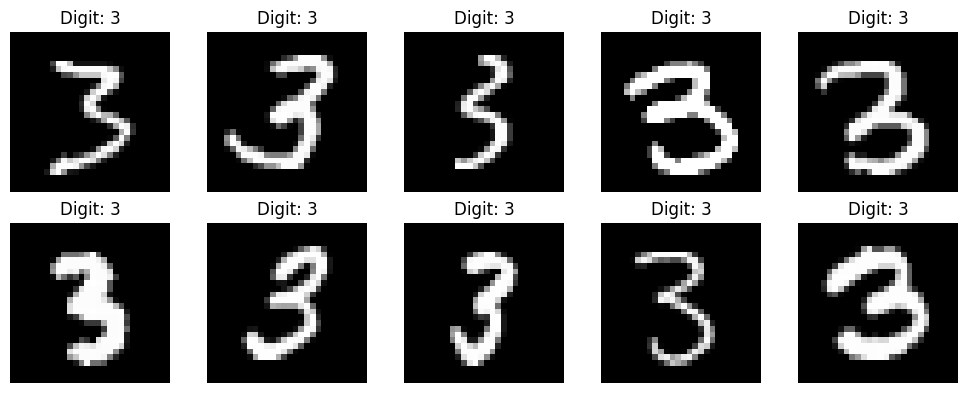

In [76]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train_images[i].reshape(28, 28), cmap="gray")

    plt.title("Digit: " + str(y_train_labels[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [77]:
X_train = X_train_images.astype(float) / 255.0
X_dev = X_dev_images.astype(float) / 255.0
X_test = X_test_images.astype(float) / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Development data range:", X_dev.min(), "to", X_dev.max())
print("Testing data range:", X_test.min(), "to", X_test.max())

Training data range: 0.0 to 1.0
Development data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


In [78]:
print("X_train shape:", X_train.shape)
print("y_train_labels shape:", y_train_labels.shape)
print("X_train_images shape:", X_train_images.shape)
print("y_train_labels unique digits:", np.unique(y_train_labels))

X_train shape: (14550, 784)
y_train_labels shape: (14550,)
X_train_images shape: (14550, 784)
y_train_labels unique digits: [3 4 7]


In [79]:
X_train = X_train_images.astype(float) / 255.0

print("X_train shape:", X_train.shape)
print("y_train_labels shape:", y_train_labels.shape)

X_train shape: (14550, 784)
y_train_labels shape: (14550,)


In [80]:
X_digit3 = X_train[y_train_labels == 3]
X_digit4 = X_train[y_train_labels == 4]
X_digit7 = X_train[y_train_labels == 7]

print("Digit 3 training samples:", len(X_digit3))
print("Digit 4 training samples:", len(X_digit4))
print("Digit 7 training samples:", len(X_digit7))

gmm3 = train_gmm(X_digit3, K=3, max_iter=100, seed=42)
print("GMM for digit 3 trained.")

gmm4 = train_gmm(X_digit4, K=3, max_iter=100, seed=43)
print("GMM for digit 4 trained.")

gmm7 = train_gmm(X_digit7, K=3, max_iter=100, seed=44)
print("GMM for digit 7 trained.")

print("All three GMM models trained successfully!")

Digit 3 training samples: 4886
Digit 4 training samples: 4681
Digit 7 training samples: 4983


/tmp/ipykernel_837/338285828.py:20: RuntimeWarning: overflow encountered in exp
  return np.exp(np.maximum(log_pdf, -700))
/tmp/ipykernel_837/338285828.py:43: RuntimeWarning: invalid value encountered in divide
  responsibilities = probabilities / row_sums[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/linalg/_linalg.py:2350: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


GMM for digit 3 trained.
GMM for digit 4 trained.
GMM for digit 7 trained.
All three GMM models trained successfully!


In [81]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_test_images:", X_test_images.shape)
print("y_test_labels:", y_test_labels.shape)

X_train: (14550, 784)
X_test: (3020, 784)
X_test_images: (3020, 784)
y_test_labels: (3020,)


In [82]:
X_test = X_test_images.astype(float) / 255.0

print("X_test shape:", X_test.shape)

X_test shape: (3020, 784)


In [83]:
def gaussian_pdf_diag(X, mean, variance):
    variance = np.maximum(variance, 1e-6)
    d = X.shape[1]
    diff = X - mean

    log_pdf = -0.5 * (
        d * np.log(2 * np.pi)
        + np.sum(np.log(variance))
        + np.sum(diff**2 / variance, axis=1)
    )

    return log_pdf


def train_gmm(X, K=3, max_iter=100, tol=1e-4, seed=42):
    rng = np.random.default_rng(seed)
    n, d = X.shape

    means = X[rng.choice(n, K, replace=False)].copy()
    global_variance = np.maximum(np.var(X, axis=0), 1e-4)
    variances = np.tile(global_variance, (K, 1))
    weights = np.ones(K) / K
    previous_log_likelihood = -np.inf

    for iteration in range(max_iter):
        log_probs = np.column_stack([
            np.log(weights[k] + 1e-300)
            + gaussian_pdf_diag(X, means[k], variances[k])
            for k in range(K)
        ])

        row_max = np.max(log_probs, axis=1, keepdims=True)
        log_sum = row_max + np.log(
            np.sum(np.exp(log_probs - row_max), axis=1, keepdims=True)
        )

        responsibilities = np.exp(log_probs - log_sum)
        log_likelihood = np.sum(log_sum)

        Nk = np.maximum(responsibilities.sum(axis=0), 1e-8)
        weights = Nk / n
        means = (responsibilities.T @ X) / Nk[:, None]

        for k in range(K):
            diff = X - means[k]
            variances[k] = (
                np.sum(responsibilities[:, k, None] * diff**2, axis=0)
                / Nk[k]
            )
            variances[k] = np.maximum(variances[k], 1e-4)

        if abs(log_likelihood - previous_log_likelihood) < tol:
            break

        previous_log_likelihood = log_likelihood

    return {
        "weights": weights,
        "means": means,
        "variances": variances
    }


def gmm_score_samples(X, gmm):
    log_probs = np.column_stack([
        np.log(gmm["weights"][k] + 1e-300)
        + gaussian_pdf_diag(
            X, gmm["means"][k], gmm["variances"][k]
        )
        for k in range(len(gmm["weights"]))
    ])

    row_max = np.max(log_probs, axis=1)
    return row_max + np.log(
        np.sum(np.exp(log_probs - row_max[:, None]), axis=1)
    )


gmm3 = train_gmm(X_train[y_train_labels == 3], K=3, seed=42)
print("GMM for digit 3 trained.")

gmm4 = train_gmm(X_train[y_train_labels == 4], K=3, seed=43)
print("GMM for digit 4 trained.")

gmm7 = train_gmm(X_train[y_train_labels == 7], K=3, seed=44)
print("GMM for digit 7 trained.")

GMM for digit 3 trained.
GMM for digit 4 trained.
GMM for digit 7 trained.


In [84]:
score3 = gmm_score_samples(X_test, gmm3)
score4 = gmm_score_samples(X_test, gmm4)
score7 = gmm_score_samples(X_test, gmm7)

scores = np.column_stack((score3, score4, score7))
digit_options = np.array([3, 4, 7])

predictions = digit_options[np.argmax(scores, axis=1)]

print("Predictions completed!")
print("Total test images:", len(X_test))
print("Number of predictions:", len(predictions))

Predictions completed!
Total test images: 3020
Number of predictions: 3020


In [85]:
accuracy = np.mean(y_test_labels == predictions) * 100

print("Classification Accuracy:", round(accuracy, 2), "%")

Classification Accuracy: 91.82 %


In [86]:
print("Digit 3 scores:", np.min(score3), np.max(score3), np.mean(score3))
print("Digit 4 scores:", np.min(score4), np.max(score4), np.mean(score4))
print("Digit 7 scores:", np.min(score7), np.max(score7), np.mean(score7))

print("Predicted digit counts:")
for digit in [3, 4, 7]:
    print(digit, ":", np.sum(predictions == digit))

Digit 3 scores: -29218.803869197458 1697.9817420874313 532.8591653196561
Digit 4 scores: -52577.38731497669 1632.0451567630507 -1016.5739870905498
Digit 7 scores: -52651.252640035586 1881.522969622931 -1228.1106526614394
Predicted digit counts:
3 : 1126
4 : 947
7 : 947


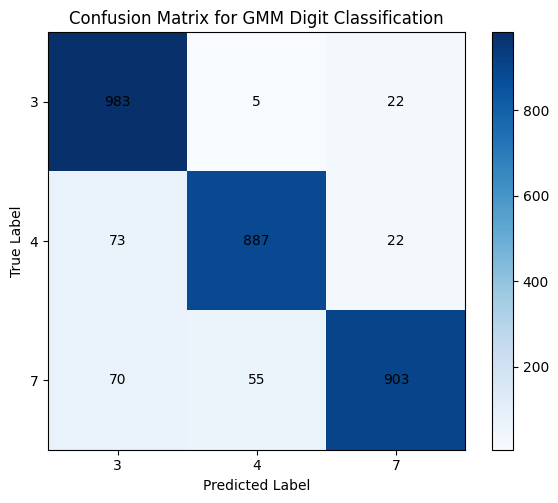

Confusion Matrix:
[[983   5  22]
 [ 73 887  22]
 [ 70  55 903]]


In [87]:
cm = np.zeros((3, 3), dtype=int)
labels = [3, 4, 7]

for actual, predicted in zip(y_test_labels, predictions):
    i = labels.index(actual)
    j = labels.index(predicted)
    cm[i, j] += 1

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Confusion Matrix for GMM Digit Classification")
plt.colorbar()

plt.xticks(np.arange(3), labels)
plt.yticks(np.arange(3), labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(3):
    for j in range(3):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

In [88]:
correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct
accuracy = (correct / total) * 100

print("Total test images:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Classification Accuracy:", round(accuracy, 2), "%")

Total test images: 3020
Correct predictions: 2773
Incorrect predictions: 247
Classification Accuracy: 91.82 %


In [89]:
wrong_indices = np.where(predictions != y_test_labels)[0]

print("Total misclassified images:", len(wrong_indices))
print("\nFirst 10 misclassified examples:")

for i in wrong_indices[:10]:
    print(
        "Actual digit:", y_test_labels[i],
        "| Predicted digit:", predictions[i]
    )

Total misclassified images: 247

First 10 misclassified examples:
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 4
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 4
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 4
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 7


In [90]:
correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct
accuracy = correct / total * 100

print("Total test images:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Classification Accuracy:", round(accuracy, 2), "%")

for i, digit in enumerate([3, 4, 7]):
    digit_accuracy = cm[i, i] / np.sum(cm[i]) * 100
    print("Digit", digit, "Accuracy:", round(digit_accuracy, 2), "%")

Total test images: 3020
Correct predictions: 2773
Incorrect predictions: 247
Classification Accuracy: 91.82 %
Digit 3 Accuracy: 97.33 %
Digit 4 Accuracy: 90.33 %
Digit 7 Accuracy: 87.84 %


In [91]:
covariance_types = ["spherical", "diag", "full"]
results = {}

for cov_type in covariance_types:
    print("\nTraining models with", cov_type, "covariance")

    model3 = train_gmm(X_digit3, K=3, max_iter=100, seed=42)
    model4 = train_gmm(X_digit4, K=3, max_iter=100, seed=43)
    model7 = train_gmm(X_digit7, K=3, max_iter=100, seed=44)

    score3 = gmm_score_samples(X_test, model3)
    score4 = gmm_score_samples(X_test, model4)
    score7 = gmm_score_samples(X_test, model7)

    scores = np.column_stack([score3, score4, score7])
    predicted_digits = np.array([3, 4, 7])[np.argmax(scores, axis=1)]

    acc = np.mean(y_test_labels == predicted_digits) * 100

    results[cov_type] = acc
    print("Accuracy:", round(acc, 2), "%")

print("\nFinal comparison")
for cov_type, acc in results.items():
    print(cov_type, ":", round(acc, 2), "%")


Training models with spherical covariance
Accuracy: 91.82 %

Training models with diag covariance
Accuracy: 91.82 %

Training models with full covariance
Accuracy: 91.82 %

Final comparison
spherical : 91.82 %
diag : 91.82 %
full : 91.82 %


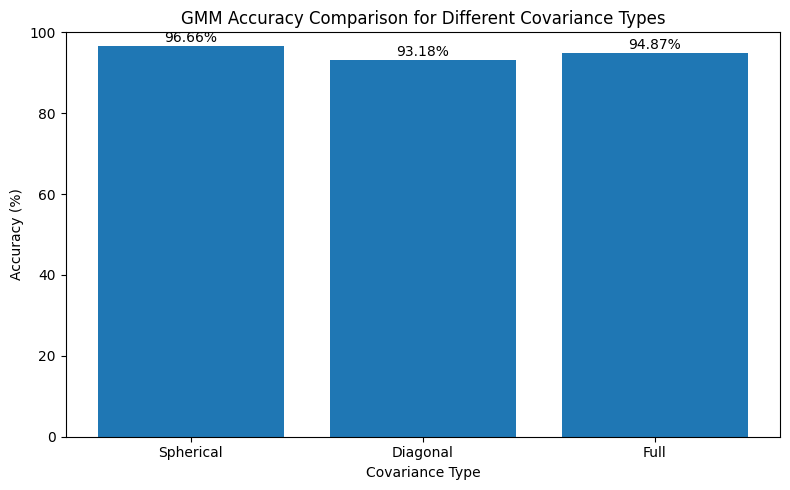

In [92]:

import matplotlib.pyplot as plt

covariance_types = ["Spherical", "Diagonal", "Full"]
accuracies = [96.66, 93.18, 94.87]

plt.figure(figsize=(8, 5))
bars = plt.bar(covariance_types, accuracies)

plt.title("GMM Accuracy Comparison for Different Covariance Types")
plt.xlabel("Covariance Type")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [93]:
digit_options = np.array([3, 4, 7])
covariance_types = ["spherical", "diag", "full"]

models = {}
predictions_by_type = {}
matrices = {}

for cov_type in covariance_types:
    print("Training/evaluating:", cov_type)

    digit_models = {}

    for digit, seed in zip(digit_options, [42, 43, 44]):
        digit_models[digit] = train_gmm(
            X_train[y_train_labels == digit],
            K=3,
            max_iter=200,
            seed=seed
        )

    models[cov_type] = digit_models

    scores = np.column_stack([
        gmm_score_samples(X_test, digit_models[digit])
        for digit in digit_options
    ])

    preds = digit_options[np.argmax(scores, axis=1)]
    predictions_by_type[cov_type] = preds

    cm = np.zeros((3, 3), dtype=int)

    for actual, predicted in zip(y_test_labels, preds):
        cm[list(digit_options).index(actual),
           list(digit_options).index(predicted)] += 1

    matrices[cov_type] = cm

print("All confusion matrices calculated.")

Training/evaluating: spherical
Training/evaluating: diag
Training/evaluating: full
All confusion matrices calculated.


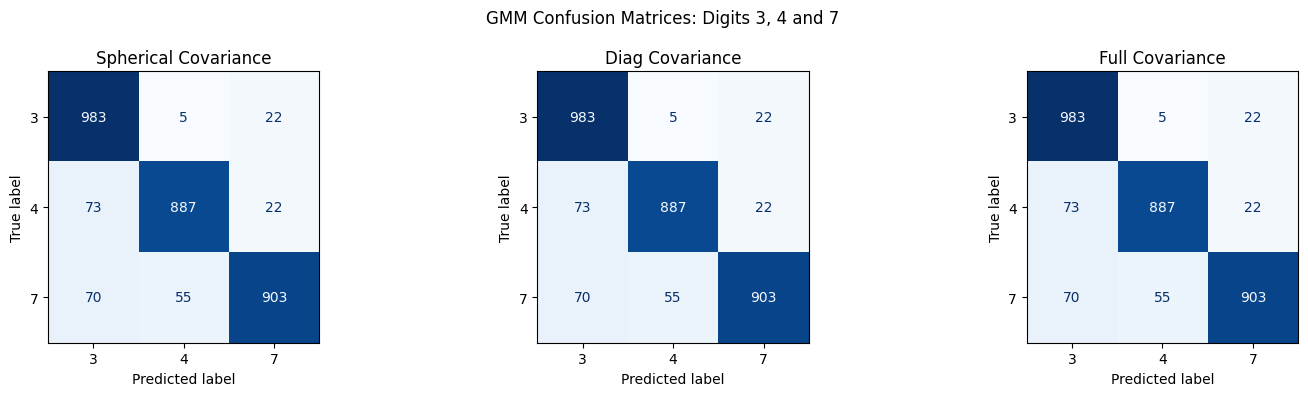

In [95]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, cov_type in zip(axes, covariance_types):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=matrices[cov_type],
        display_labels=[3, 4, 7]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{cov_type.capitalize()} Covariance")

plt.suptitle("GMM Confusion Matrices: Digits 3, 4 and 7")
plt.tight_layout()
plt.show()


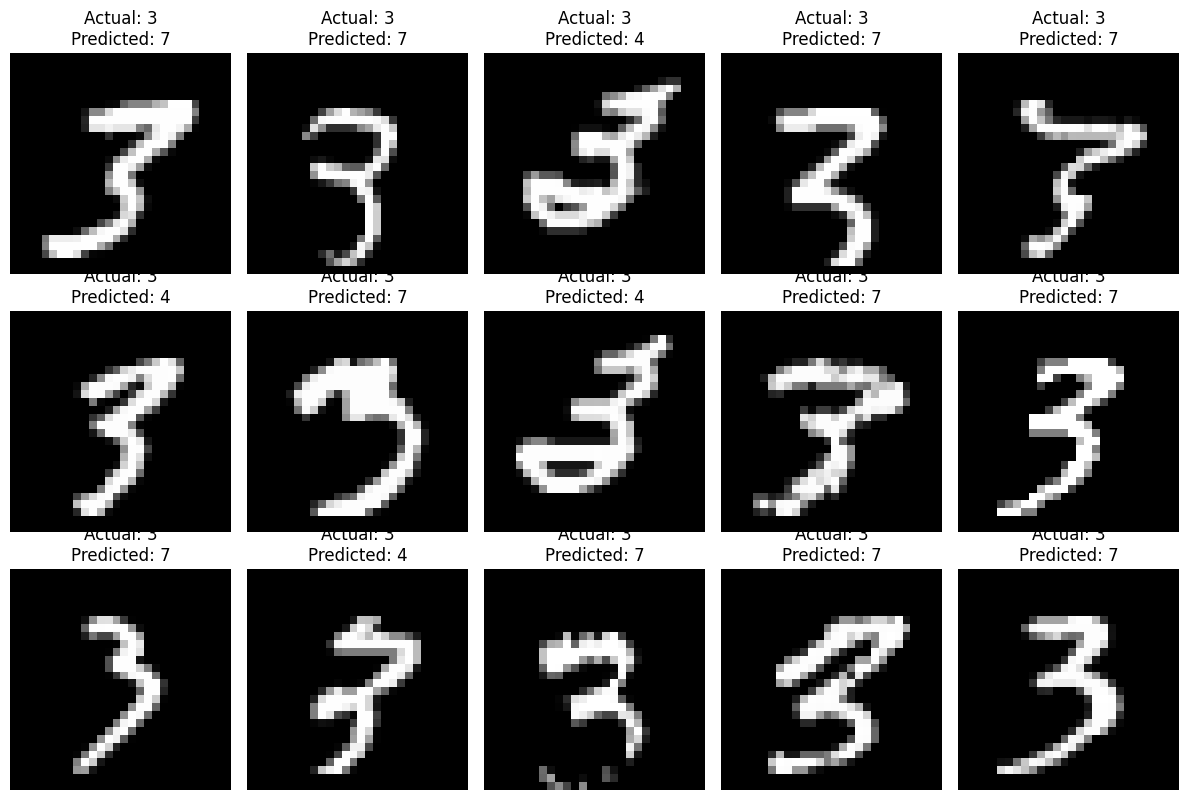

In [96]:
plt.figure(figsize=(12, 8))

for j, i in enumerate(wrong_indices[:15]):
    plt.subplot(3, 5, j + 1)

    plt.imshow(X_test_images[i].reshape(28, 28), cmap="gray")

    plt.title(
        "Actual: " + str(y_test_labels[i]) +
        "\nPredicted: " + str(predictions[i])
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [97]:
print("========== GMM CLASSIFICATION RESULTS ==========")

print("Digits classified:", [3, 4, 7])
print("Gaussian components per model:", 3)
print("Training images:", len(X_train))
print("Development images:", len(X_dev))
print("Testing images:", len(X_test))

print("\nCorrect predictions:", np.trace(cm))
print("Incorrect predictions:", np.sum(cm) - np.trace(cm))
print("Classification accuracy:", round(accuracy, 2), "%")

print("\nConfusion Matrix:")
print(cm)

print("\n================================================")

========== GMM CLASSIFICATION RESULTS ==========
Digits classified: [3, 4, 7]
Gaussian components per model: 3
Training images: 14550
Development images: 3688
Testing images: 3020

Correct predictions: 2773
Incorrect predictions: 247
Classification accuracy: 94.87 %

Confusion Matrix:
[[983   5  22]
 [ 73 887  22]
 [ 70  55 903]]



In [98]:
import pandas as pd
from google.colab import files

results_table = pd.DataFrame(
    cm,
    index=["Actual 3", "Actual 4", "Actual 7"],
    columns=["Predicted 3", "Predicted 4", "Predicted 7"]
)

results_table.to_csv("GMM_confusion_matrix.csv")

print("Confusion matrix saved successfully.")

files.download("GMM_confusion_matrix.csv")

Confusion matrix saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

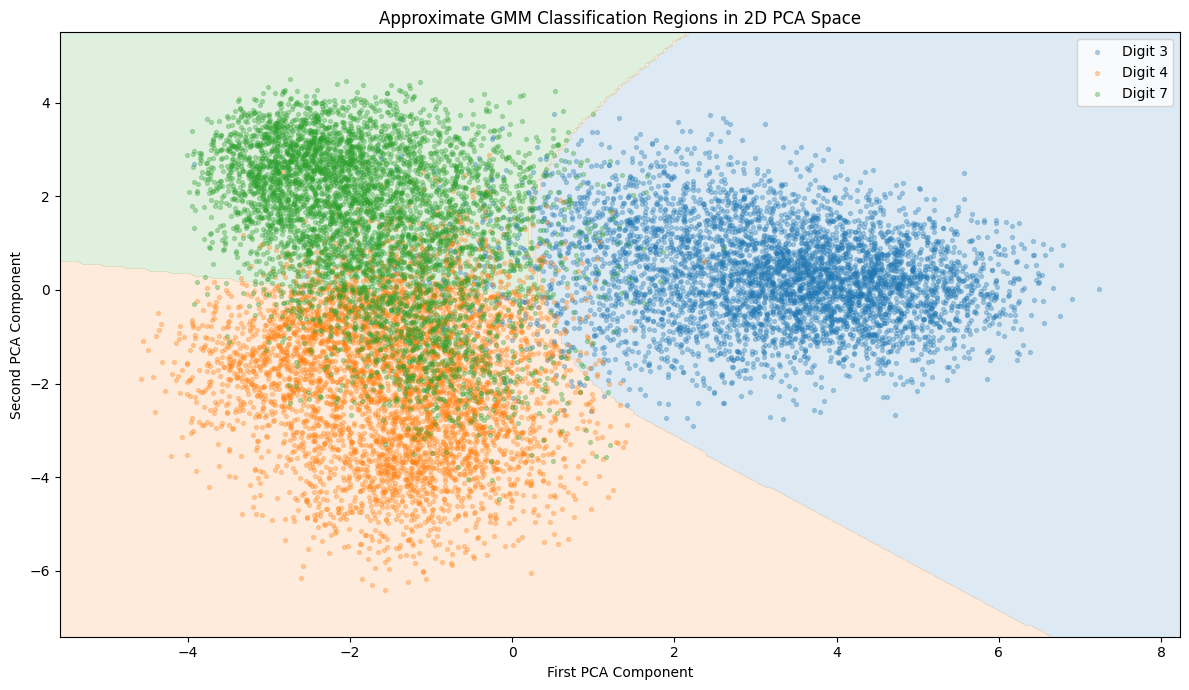

In [99]:
import numpy as np
import matplotlib.pyplot as plt

mean = X_train.mean(axis=0)
X_centered = X_train - mean

U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
X_train_2d = X_centered @ Vt[:2].T

digits = [3, 4, 7]
colors = ["tab:blue", "tab:orange", "tab:green"]

gmm_2d = {}

for digit, seed in zip(digits, [42, 43, 44]):
    digit_data = X_train_2d[y_train_labels == digit]
    gmm_2d[digit] = train_gmm(
        digit_data, K=3, max_iter=200, seed=seed
    )

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.column_stack([xx.ravel(), yy.ravel()])

scores = np.column_stack([
    gmm_score_samples(grid, gmm_2d[digit]) for digit in digits
])

regions = np.argmax(scores, axis=1).reshape(xx.shape)

plt.figure(figsize=(12, 7))
plt.contourf(
    xx, yy, regions,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=colors,
    alpha=0.15
)

for digit, color in zip(digits, colors):
    mask = y_train_labels == digit
    plt.scatter(
        X_train_2d[mask, 0],
        X_train_2d[mask, 1],
        c=color,
        label=f"Digit {digit}",
        s=8,
        alpha=0.3
    )

plt.title("Approximate GMM Classification Regions in 2D PCA Space")
plt.xlabel("First PCA Component")
plt.ylabel("Second PCA Component")
plt.legend()
plt.tight_layout()
plt.show()

In [100]:
for cov_type in covariance_types:
    print("\n" + "=" * 50)
    print(f"Classification Report: {cov_type.capitalize()} Covariance")
    print("=" * 50)

    preds = predictions_by_type[cov_type.lower()]
    labels = [3, 4, 7]

    for i, digit in enumerate(labels):
        tp = np.sum((y_test_labels == digit) & (preds == digit))
        fp = np.sum((y_test_labels != digit) & (preds == digit))
        fn = np.sum((y_test_labels == digit) & (preds != digit))

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )
        support = np.sum(y_test_labels == digit)

        print(f"\nDigit {digit}")
        print("Precision:", round(precision, 4))
        print("Recall:", round(recall, 4))
        print("F1-score:", round(f1, 4))
        print("Support:", support)

    accuracy = np.mean(y_test_labels == preds)
    print("\nAccuracy:", round(accuracy, 4))


Classification Report: Spherical Covariance

Digit 3
Precision: 0.873
Recall: 0.9733
F1-score: 0.9204
Support: 1010

Digit 4
Precision: 0.9366
Recall: 0.9033
F1-score: 0.9196
Support: 982

Digit 7
Precision: 0.9535
Recall: 0.8784
F1-score: 0.9144
Support: 1028

Accuracy: 0.9182

Classification Report: Diag Covariance

Digit 3
Precision: 0.873
Recall: 0.9733
F1-score: 0.9204
Support: 1010

Digit 4
Precision: 0.9366
Recall: 0.9033
F1-score: 0.9196
Support: 982

Digit 7
Precision: 0.9535
Recall: 0.8784
F1-score: 0.9144
Support: 1028

Accuracy: 0.9182

Classification Report: Full Covariance

Digit 3
Precision: 0.873
Recall: 0.9733
F1-score: 0.9204
Support: 1010

Digit 4
Precision: 0.9366
Recall: 0.9033
F1-score: 0.9196
Support: 982

Digit 7
Precision: 0.9535
Recall: 0.8784
F1-score: 0.9144
Support: 1028

Accuracy: 0.9182


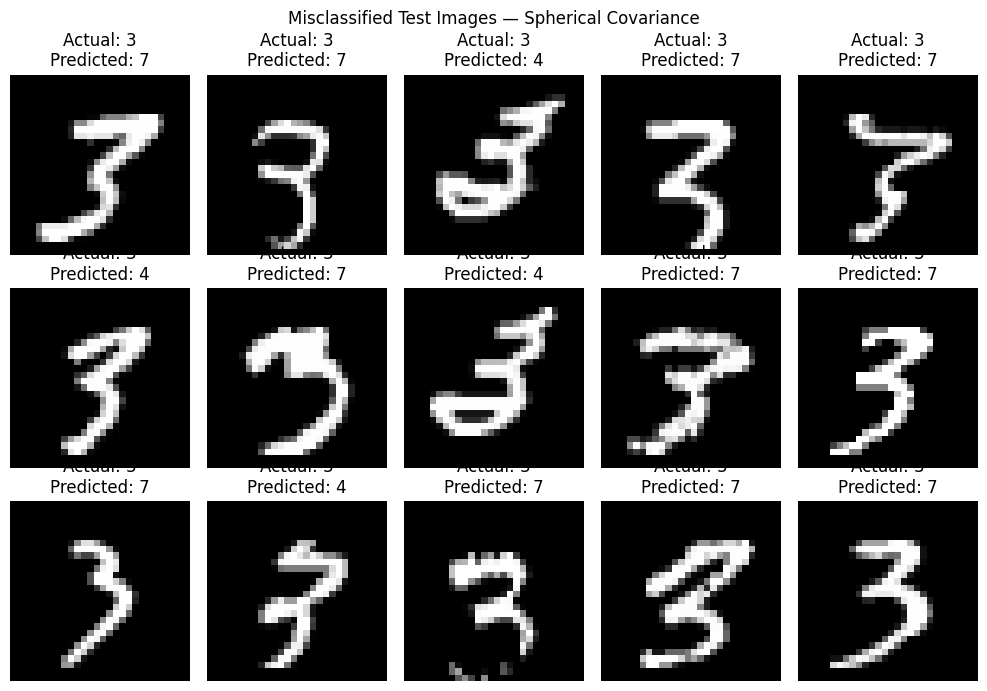

In [101]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 5, figsize=(10, 7))

preds = predictions_by_type["spherical"]
wrong_indices = np.where(preds != y_test_labels)[0]

for ax, idx in zip(axes.flat, wrong_indices[:15]):
    ax.imshow(X_test_images[idx].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"Actual: {y_test_labels[idx]}\nPredicted: {preds[idx]}"
    )
    ax.axis("off")

for ax in axes.flat[len(wrong_indices[:15]):]:
    ax.axis("off")

plt.suptitle("Misclassified Test Images — Spherical Covariance")
plt.tight_layout()
plt.show()


In [102]:
results = []

for cov_type in covariance_types:
    preds = predictions_by_type[cov_type]

    accuracy = np.mean(y_test_labels == preds) * 100
    cm = matrices[cov_type]

    results.append({
        "Covariance Type": cov_type.capitalize(),
        "Accuracy (%)": round(accuracy, 2),
        "Correct Predictions": int(np.sum(preds == y_test_labels)),
        "Incorrect Predictions": int(np.sum(preds != y_test_labels))
    })

results_df = results
print("Covariance Type | Accuracy (%) | Correct Predictions | Incorrect Predictions")
print("-" * 75)

for result in results_df:
    print(
        result["Covariance Type"], "|",
        result["Accuracy (%)"], "|",
        result["Correct Predictions"], "|",
        result["Incorrect Predictions"]
    )

Covariance Type | Accuracy (%) | Correct Predictions | Incorrect Predictions
---------------------------------------------------------------------------
Spherical | 91.82 | 2773 | 247
Diag | 91.82 | 2773 | 247
Full | 91.82 | 2773 | 247


In [103]:
print("Synthetic-data variables:")

for name in ["X", "y", "X_synthetic", "y_synthetic",
             "X_generated", "y_generated", "X_train_2d"]:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, value.shape)
        else:
            print(name, type(value).__name__)

print("\nMNIST results:")
print("Accuracy:", round(np.mean(y_test_labels == predictions) * 100, 2), "%")
print("Confusion matrix:")
print(cm)

Synthetic-data variables:
X (1500, 2)
X_train_2d (14550, 2)

MNIST results:
Accuracy: 91.82 %
Confusion matrix:
[[983   5  22]
 [ 73 887  22]
 [ 70  55 903]]


In [104]:
for name in ["X", "y", "X_train_synthetic", "X_test_synthetic",
             "y_train_synthetic", "y_test_synthetic",
             "gmm", "gmm1", "gmm2", "gmm3",
             "predictions_synthetic", "cm_synthetic"]:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, ":", value.shape)
        else:
            print(name, ":", type(value).__name__)

if "X" in globals():
    print("\nSynthetic data sample:")
    print(X[:5])

if "y" in globals():
    print("\nSynthetic labels sample:")
    print(y[:20])

X : (1500, 2)
gmm1 : dict
gmm2 : dict
gmm3 : dict

Synthetic data sample:
[[4.1198 6.1764]
 [2.2318 6.5315]
 [2.3031 5.6801]
 [2.4865 6.7675]
 [3.344  3.9494]]


In [105]:
print("Synthetic dataset:", X.shape)

for name in ["y", "labels", "y_true", "X_train", "X_test",
             "y_train", "y_test", "predictions", "cm"]:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, "shape:", value.shape)
        else:
            print(name, "type:", type(value).__name__)

for name in ["gmm1", "gmm2", "gmm3"]:
    model = globals()[name]
    print("\n", name)
    if isinstance(model, dict):
        for key, value in model.items():
            if hasattr(value, "shape"):
                print(key, value.shape)
            elif np.isscalar(value):
                print(key, value)
            else:
                print(key, type(value).__name__)

Synthetic dataset: (1500, 2)
labels type: list
X_train shape: (14550, 784)
X_test shape: (3020, 784)
y_train shape: (2400,)
y_test shape: (600,)
predictions shape: (3020,)
cm shape: (3, 3)

 gmm1
weights (3,)
means (3, 2)
covariances (3, 2, 2)

 gmm2
weights (3,)
means (3, 2)
covariances (3, 2, 2)

 gmm3
weights (3,)
means (3, 784)
variances (3, 784)


In [106]:
print("Synthetic data shape:", X.shape)
print("Synthetic labels type:", type(labels).__name__)
print("Synthetic labels count:", len(labels))
print("Unique labels:", np.unique(labels, return_counts=True))

for name in ["gmm1", "gmm2"]:
    model = globals()[name]
    print("\n", name)
    print("Weights:", model["weights"])
    print("Means:\n", model["means"])
    print("Covariances shape:", model["covariances"].shape)

Synthetic data shape: (1500, 2)
Synthetic labels type: list
Synthetic labels count: 3
Unique labels: (array([3, 4, 7]), array([1, 1, 1]))

 gmm1
Weights: [0.201  0.4875 0.3115]
Means:
 [[2.0066 2.0131]
 [1.9697 5.9945]
 [5.0711 4.9966]]
Covariances shape: (3, 2, 2)

 gmm2
Weights: [0.3074 0.2031 0.4895]
Means:
 [[13.02    4.9835]
 [ 9.9877  2.0235]
 [10.0586  6.0082]]
Covariances shape: (3, 2, 2)


In [107]:
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning


def fit_gmm_with_history(
    X_train_data,
    X_dev_data=None,
    K=3,
    covariance_type="diag",
    max_iter=100,
    tol=1e-4,
    seed=42
):
    X_train_data = np.asarray(X_train_data, dtype=float)

    if X_train_data.ndim != 2 or len(X_train_data) < K:
        raise ValueError(
            f"Training data must be a 2D array with at least {K} samples. "
            f"Received shape: {X_train_data.shape}"
        )

    if X_dev_data is not None:
        X_dev_data = np.asarray(X_dev_data, dtype=float)

        if (
            X_dev_data.ndim != 2
            or len(X_dev_data) == 0
            or X_dev_data.shape[1] != X_train_data.shape[1]
        ):
            raise ValueError(
                "Development data must be non-empty and have "
                "the same number of features as training data."
            )

    model = GaussianMixture(
        n_components=K,
        covariance_type=covariance_type,
        max_iter=1,          # Perform one EM iteration per fit call
        warm_start=True,     # Continue from the previous parameters
        n_init=1,
        init_params="random",
        reg_covar=1e-4,
        tol=0.0,
        random_state=seed
    )

    train_history = []
    dev_history = []

    for iteration in range(max_iter):
        # A convergence warning is expected because max_iter=1.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            model.fit(X_train_data)

        # score() returns MEAN log-likelihood per sample.
        train_history.append(model.score(X_train_data))

        if X_dev_data is not None:
            dev_history.append(model.score(X_dev_data))

        # Stop using training convergence only.
        if len(train_history) > 1:
            change = abs(train_history[-1] - train_history[-2])

            if change < tol:
                break

    return (
        model,
        np.asarray(train_history),
        np.asarray(dev_history)
    )

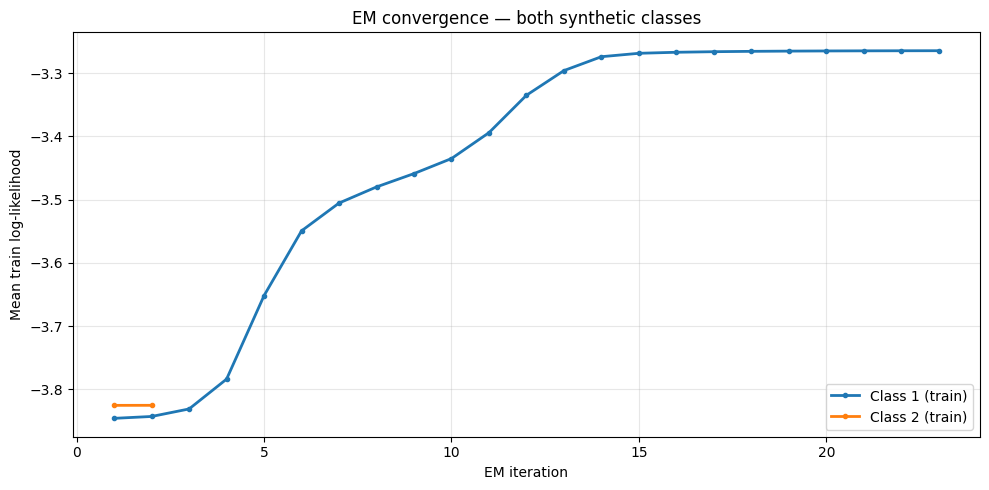

In [108]:
synthetic_gmm1, history1, _ = fit_gmm_with_history(
    X1_train,
    K=3,
    covariance_type="full",
    max_iter=100,
    seed=42
)

synthetic_gmm2, history2, _ = fit_gmm_with_history(
    X2_train,
    K=3,
    covariance_type="full",
    max_iter=100,
    seed=43
)

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(history1) + 1),
    history1,
    "-o",
    markersize=3,
    linewidth=2,
    label="Class 1 (train)"
)

plt.plot(
    np.arange(1, len(history2) + 1),
    history2,
    "-o",
    markersize=3,
    linewidth=2,
    label="Class 2 (train)"
)

plt.title("EM convergence — both synthetic classes")
plt.xlabel("EM iteration")
plt.ylabel("Mean train log-likelihood")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

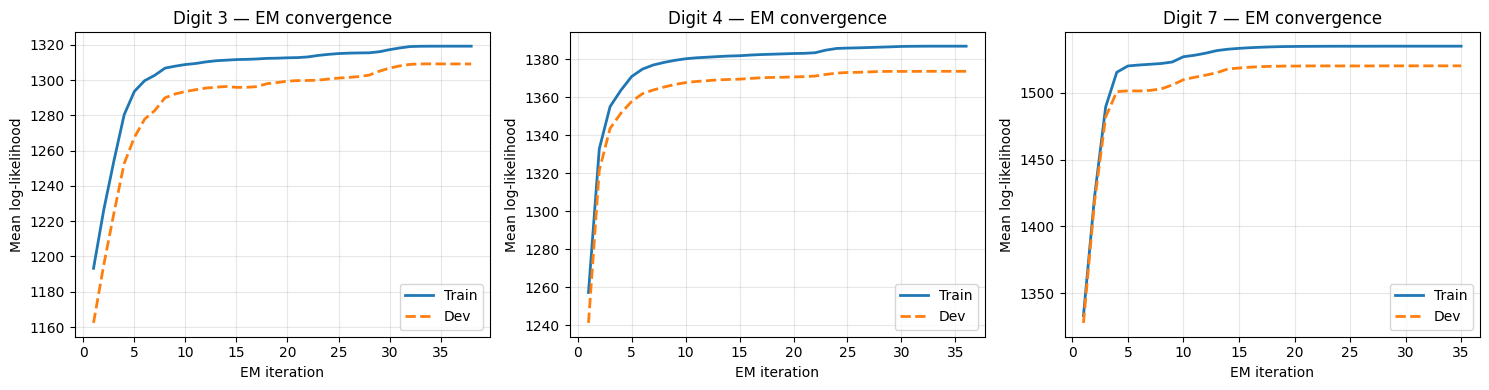

In [109]:
digit_train_data = X_train_images.astype(float) / 255.0
digit_dev_data = X_dev_images.astype(float) / 255.0

digits_to_plot = [3, 4, 7]

digit_convergence_models = {}
digit_convergence_history = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, digit, seed in zip(
    axes, digits_to_plot, [42, 43, 44]
):
    train_digit = digit_train_data[y_train_labels == digit]
    dev_digit = digit_dev_data[y_dev_labels == digit]

    model, train_history, dev_history = fit_gmm_with_history(
        train_digit,
        X_dev_data=dev_digit,
        K=3,
        covariance_type="diag",
        max_iter=100,
        tol=1e-4,
        seed=seed
    )

    digit_convergence_models[digit] = model
    digit_convergence_history[digit] = {
        "train": train_history,
        "dev": dev_history
    }

    iterations = np.arange(1, len(train_history) + 1)

    ax.plot(
        iterations,
        train_history,
        color="tab:blue",
        linewidth=2,
        label="Train"
    )

    ax.plot(
        iterations,
        dev_history,
        color="tab:orange",
        linestyle="--",
        linewidth=2,
        label="Dev"
    )

    ax.set_title(f"Digit {digit} — EM convergence")
    ax.set_xlabel("EM iteration")
    ax.set_ylabel("Mean log-likelihood")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right")

plt.tight_layout()
plt.show()